# Table of Contents
- 1. Defining Primary and Guardrail Metrics
- 2. Power Analysis, Significance Level, and Effect Size
- 3. Sample Size and Duration Calculation
- 4. Randomization Units (User-level vs Session-level)

In [2]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for experiment design and sample size loaded successfully.")

Global libraries for experiment design and sample size loaded successfully.


---
## 1. Defining Primary and Guardrail Metrics

### 1. Definition
Experiment metrics are categorized into primary metrics (capturing direct business success and user value) and guardrail metrics (monitoring safety constraints such as latency and error rates to prevent negative unintended consequences).

### 2. Math Formula
Optimization objective maximizing primary metric lift $\Delta M_{primary}$ subject to guardrail constraint threshold $\tau$:
$$\max \Delta M_{primary} \quad \text{subject to} \quad G_{guardrail} \le \tau$$

### 3. Notation Pronunciation
- `Primary Metric`: "Core business success indicator (e.g., checkout conversion rate)"
- `Guardrail Metric`: "Safety constraint metric (e.g., page load latency or error rate)"

### 4. Naive Example
Tracking checkout click-through rate as the primary metric while monitoring server latency as a guardrail metric to ensure faster features don't crash the database.

### 5. Uses
- Balancing growth initiatives against user experience and system stability.
- Preventing metric hacking and unintended regressions.
- Establishing clear decision criteria for A/B test rollouts.

Experiment Metrics Monitoring Summary:
             Metric_Type  Target_Threshold  Observed_Value
0  Primary (Conversion)              0.15           0.162
1   Guardrail (Latency)            200.00         185.000
2    Guardrail (Errors)              0.01           0.004


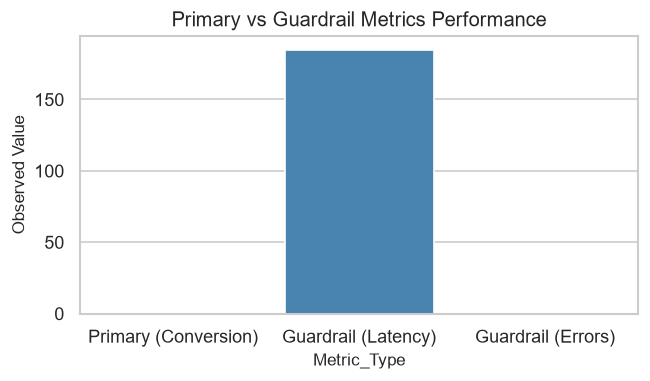

In [3]:
# 6. & 7. Implementation and Visualization
df_metrics = pd.DataFrame({
    'Metric_Type': ['Primary (Conversion)', 'Guardrail (Latency)', 'Guardrail (Errors)'],
    'Target_Threshold': [0.15, 200, 0.01],
    'Observed_Value': [0.162, 185, 0.004]
})
print("Experiment Metrics Monitoring Summary:\n", df_metrics)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='Metric_Type', y='Observed_Value', hue='Metric_Type', data=df_metrics, palette='Blues_d', legend=False, errorbar=None)
plt.title('Primary vs Guardrail Metrics Performance')
plt.ylabel('Observed Value')
plt.show()

---
## 2. Power Analysis, Significance Level, and Effect Size

### 1. Definition
Power analysis links significance level ($\\alpha$), statistical power ($1 - \\beta$), and minimum detectable effect size (MDE) to determine the probability of detecting a true experimental effect without false positives.

### 2. Math Formula
Relationship between Type I error $\\alpha$, Type II error $\\beta$, sample size $n$, and effect size $\\delta$:
$$Z_{1-\beta} + Z_{1-\alpha/2} = \frac{\\delta}{\\sigma \\sqrt{\frac{2}{n}}}$$

### 3. Notation Pronunciation
- `Alpha` ($\\alpha$): "Type I error probability (false positive rate, typically 0.05)"
- `Power` ($1 - \\beta$): "Probability of detecting a true effect (typically 0.80)"

### 4. Naive Example
Setting significance at 0.05 and power at 0.80 to ensure our A/B test reliably detects a 2% lift in subscription sign-ups.

### 5. Uses
- Preventing underpowered experiments that miss genuine business impacts.
- Calibrating sample size requirements prior to test launch.
- Managing statistical risk in executive decision-making.

Power Analysis Parameters -> Alpha: 0.05, Power: 0.8, MDE: 0.02


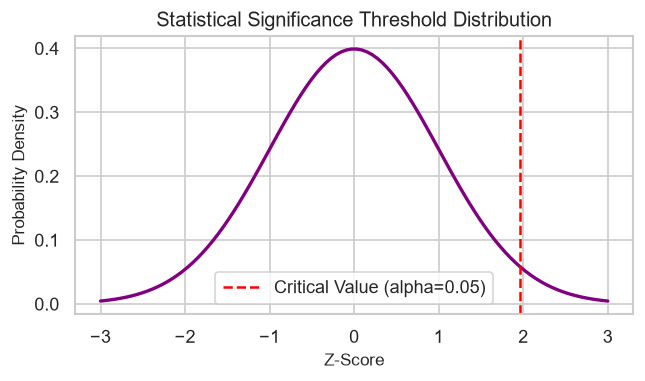

In [4]:
# 6. & 7. Implementation and Visualization
alpha = 0.05
power = 0.80
mde = 0.02 # Minimum detectable effect
print(f"Power Analysis Parameters -> Alpha: {alpha}, Power: {power}, MDE: {mde}")

# Visualization of Z-distribution critical regions
x_vals = np.linspace(-3, 3, 100)
y_vals = stats.norm.pdf(x_vals)
plt.figure(figsize=(6, 3))
sns.lineplot(x=x_vals, y=y_vals, color='purple', linewidth=2)
plt.axvline(x=1.96, color='red', linestyle='--', label='Critical Value (alpha=0.05)')
plt.title('Statistical Significance Threshold Distribution')
plt.xlabel('Z-Score')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

---
## 3. Sample Size and Duration Calculation

### 1. Definition
Sample size calculations determine the required number of observations per variant, which translates directly into experiment duration based on daily incoming user traffic volume.

### 2. Math Formula
Required sample size per variant $n$ based on variance $\\sigma^2$ and minimum detectable effect $\\delta$:
$$n \\approx \\frac{2(Z_{1-\alpha/2} + Z_{1-\beta})^2 \\sigma^2}{\delta^2}$$

### 3. Notation Pronunciation
- `Sample Size per Variant` ($n$): "Required participant count per test group"
- `Experiment Duration` ($D$): "Total sample size divided by daily incoming traffic"

### 4. Naive Example
Calculating that 40,000 users are required per variant; with 4,000 daily visitors, the experiment must run for at least 20 days to account for weekly seasonality.
### 5. Uses
- Planning experiment roadmaps and engineering timelines.
- Avoiding peeking and premature stopping errors.
- Ensuring robust data collection across business cycles.

Required Sample per Variant: 45,000
Estimated Experiment Duration: 18 Days


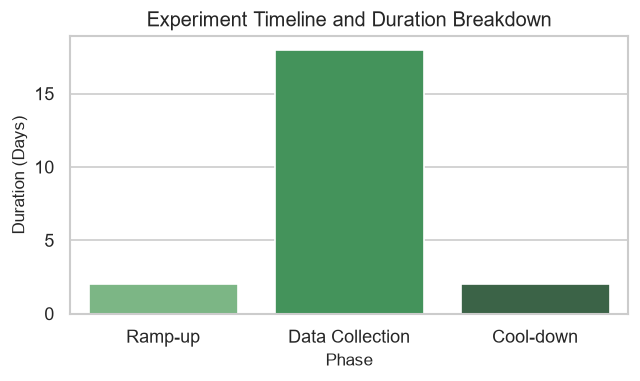

In [5]:
# 6. & 7. Implementation and Visualization
required_sample_per_variant = 45000
daily_traffic = 5000
estimated_days = np.ceil((required_sample_per_variant * 2) / daily_traffic)
print(f"Required Sample per Variant: {required_sample_per_variant:,}")
print(f"Estimated Experiment Duration: {int(estimated_days)} Days")

# Visualization
df_duration = pd.DataFrame({
    'Phase': ['Ramp-up', 'Data Collection', 'Cool-down'],
    'Days': [2, int(estimated_days), 2]
})
plt.figure(figsize=(6, 3))
sns.barplot(x='Phase', y='Days', hue='Phase', data=df_duration, palette='Greens_d', legend=False, errorbar=None)
plt.title('Experiment Timeline and Duration Breakdown')
plt.ylabel('Duration (Days)')
plt.show()

---
## 4. Randomization Units (User-level vs Session-level)

### 1. Definition
Randomization units define the entity assigned to treatment or control (e.g., user ID versus session ID); choosing the wrong unit can violate independence assumptions or cause user-experience inconsistency (flickering).

### 2. Math Formula
Effective sample size $N_{eff}$ adjustment accounting for intra-class correlation $\\rho$ and cluster size $m$:
$$N_{eff} = \frac{N}{1 + (m - 1)\\rho}$$

### 3. Notation Pronunciation
- `User-level Randomization`: "Assigned per unique user ID (prevents experience flickering)"
- `Session-level Randomization`: "Assigned per browser session (risks correlation violations)"

### 4. Naive Example
Randomizing pricing at the session level, causing a returning user to see two different prices on consecutive visits, destroying trust and violating test assumptions.
### 5. Uses
- Preventing Sample Ratio Mismatch (SRM) and statistical bias.
- Ensuring consistent user experiences across multi-device touchpoints.
- Structuring cluster-randomized experiments correctly.

Randomization Unit Comparison:
   Randomization_Unit  Consistency_Score Risk_of_Flickering
0         User-level               0.99                Low
1      Session-level               0.45               High
2       Device-level               0.85           Moderate


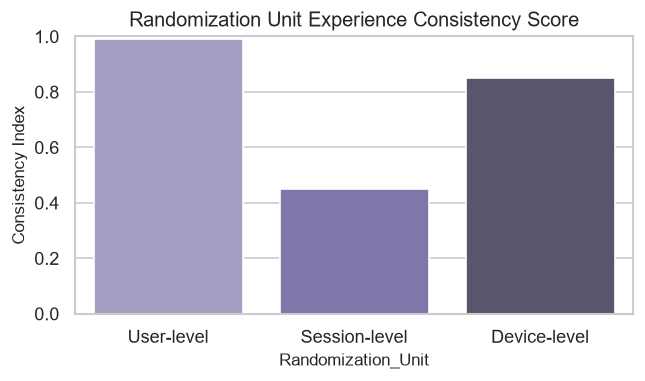

In [6]:
# 6. & 7. Implementation and Visualization
df_unit = pd.DataFrame({
    'Randomization_Unit': ['User-level', 'Session-level', 'Device-level'],
    'Consistency_Score': [0.99, 0.45, 0.85],
    'Risk_of_Flickering': ['Low', 'High', 'Moderate']
})
print("Randomization Unit Comparison:\n", df_unit)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='Randomization_Unit', y='Consistency_Score', hue='Randomization_Unit', data=df_unit, palette='Purples_d', legend=False, errorbar=None)
plt.title('Randomization Unit Experience Consistency Score')
plt.ylabel('Consistency Index')
plt.ylim(0, 1)
plt.show()

---
## Summary Table

| Experiment Design Concept | Core Formula / Criterion | Primary Objective | Business Impact |
| :--- | :--- | :--- | :--- |
| **Primary & Guardrail Metrics** | $\max \Delta M_{primary}$ s.t. $G \le \tau$ | Balancing growth and safety | Ensuring feature launches do not harm core business health |
| **Power Analysis** | $Z_{1-\beta} + Z_{1-\alpha/2} = \frac{\delta}{\sigma \sqrt{2/n}}$ | Calculating statistical risk | Preventing false positives and underpowered tests |
| **Sample Size & Duration** | $n \approx \frac{2(Z_{\alpha} + Z_{\beta})^2 \sigma^2}{\delta^2}$ | Planning experiment timelines | Avoiding premature stopping and accounting for seasonality |
| **Randomization Units** | $N_{eff} = \frac{N}{1 + (m-1)\rho}$ | Choosing assignment granularity | Preventing user flickering and statistical independence bias |